# Walkthrough: An Explainable Hybrid Ensemble Learning Framework in Healthcare Data
This notebook runs the **same code** that the full experiment uses (`src/xhe/*.py`, `scripts/04_run_confirmatory.py`), step by step on one fold of the Cleveland dataset, so you can see what happens at each stage. The last section loads the results of the full run (75 folds, 3 datasets).

Project folder: `D:\Thesis\xai-hybrid-ensemble`. Open this file in Jupyter, VS Code or Google Colab.

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=FutureWarning)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from xhe import data, cv, models, explain, metrics_xai, stats
import sklearn, shap, xgboost
print('Python', sys.version.split()[0], '| scikit-learn', sklearn.__version__, '| SHAP', shap.__version__, '| XGBoost', xgboost.__version__)
CFG = data.CONFIG; SEED = CFG['master_seed']; print('master seed', SEED)

Python 3.13.17 | scikit-learn 1.9.1 | SHAP 0.54.1 | XGBoost 3.4.1
master seed 20261026


/home/claude/venv313/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data: official UCI files, checked by SHA-256 fingerprint
`data.load()` opens the official zip, checks its fingerprint against `configs/study.yaml`, and stops if it does not match.

In [2]:
rows = []
for name, spec in CFG['datasets'].items():
    ds = data.load(name, ROOT / 'data' / 'raw' / spec['zip_name'])
    a = data.audit(ds)
    rows.append({'dataset': name, 'rows': a['rows'], 'features': a['features'], 'positives': a['positives'],
                 'negatives': a['negatives'], 'missing cells': a['missing_cells'], 'exact duplicates': a['exact_duplicate_rows']})
pd.DataFrame(rows)

,dataset,rows,features,positives,negatives,missing cells,exact duplicates
0,wdbc,569,30,212,357,0,0
1,dr_debrecen,1151,19,611,540,0,5
2,cleveland,303,13,139,164,6,0


The processed data used in the experiment (after the logged removal of 5 duplicates in DR Debrecen) and the saved cross-validation folds:

In [3]:
def load_processed(name):
    df = pd.read_csv(ROOT / 'data' / 'processed' / f'{name}.csv')
    y = df.pop('target').astype(int)
    folds = cv.load_folds(ROOT / 'data' / 'processed' / f'{name}_outer_folds.json')
    return df, y, folds, data.FEATURE_TYPES[name]
X, y, folds, ft = load_processed('cleveland')
print(X.shape, '| folds:', len(folds), '| fold 0 train/test:', len(folds[0]['train']), len(folds[0]['test']))
X.head()

(303, 13) | folds: 25 | fold 0 train/test: 242 61


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0


## 2. One outer fold: five models, S* selection and the three ensembles
`FoldModels` (in `scripts/04_run_confirmatory.py`) fits each component inside a pipeline on the training fold only, computes inner 5-fold out-of-fold probabilities, chooses **S*** (best inner AUC), and fits the meta-learners of **E2** (stacking) and **E3** (hybrid: soft-vote groups A = LR/SVM/KNN and B = RF/XGB, then stacking).

In [4]:
import importlib.util
spec = importlib.util.spec_from_file_location('runner', ROOT / 'scripts' / '04_run_confirmatory.py')
runner = importlib.util.module_from_spec(spec); spec.loader.exec_module(runner)
f0 = folds[0]
Xtr, ytr = X.iloc[f0['train']], y.iloc[f0['train']]
Xte, yte = X.iloc[f0['test']], y.iloc[f0['test']].values
t0 = time.time(); fm = runner.FoldModels(Xtr, ytr, ft, SEED); print(f'fitted in {time.time()-t0:.1f}s')
print('inner out-of-fold AUC:', {k: round(v, 3) for k, v in fm.inner_auc.items()})
print('S* =', fm.s_star, '| E3 fallback triggered:', bool(fm.e3_fallback))
print('E3 meta-learner weights (v_A, v_B):', np.round(fm.meta3.coef_.ravel(), 3))

fitted in 5.1s
inner out-of-fold AUC: {'lr': 0.921, 'svm': 0.908, 'knn': 0.905, 'rf': 0.909, 'xgb': 0.894}
S* = lr | E3 fallback triggered: False
E3 meta-learner weights (v_A, v_B): [3.15  2.091]


Check that the fast ensemble assembly gives exactly the same predictions as scikit-learn's own `VotingClassifier`/`StackingClassifier`:

In [5]:
runner.check_equivalence(Xtr, ytr, Xte, ft, fm)

{'e1': 0.0, 'e2': 0.0, 'e3': 0.0}

Test-fold performance on this one fold:

In [6]:
pd.DataFrame({m: runner.pred_metrics(yte, fm.proba(m, Xte.values)) for m in runner.ALL_MODELS + ['s_star']}).T.round(3)

,auc,brier,accuracy,precision,recall,specificity,f1
lr,0.885,0.149,0.787,0.759,0.786,0.788,0.772
svm,0.871,0.146,0.787,0.727,0.857,0.727,0.787
knn,0.891,0.133,0.803,0.808,0.750,0.848,0.778
rf,0.902,0.132,0.820,0.774,0.857,0.788,0.814
xgb,0.845,0.204,0.754,0.710,0.786,0.727,0.746
e1,0.877,0.142,0.738,0.688,0.786,0.697,0.733
e2,0.882,0.142,0.787,0.742,0.821,0.758,0.780
e3,0.877,0.145,0.738,0.688,0.786,0.697,0.733
s_star,0.885,0.149,0.787,0.759,0.786,0.788,0.772


## 3. Explaining one patient with SHAP (E3 and S*)
Permutation SHAP is applied to the **whole fitted model** (`fm.f(...)`), with 50 background rows from the training fold. The same seed is used for both models.

In [7]:
b_shap, b_del, cc_tr = runner.backgrounds(Xtr, SEED)
i = [j for j in f0['test'] if not X.iloc[j].isna().any()][0]
x = X.iloc[i].values
sh = {m: explain.permutation_shap(fm.f(m), x[None], b_shap, 500, seed=10_000 + i) for m in ['e3', 's_star']}
tab = pd.DataFrame({'value': x, 'SHAP E3': sh['e3']['values'][0], 'SHAP S*': sh['s_star']['values'][0]}, index=X.columns)
print('patient row', i, '| true class', y.iloc[i], '| P(E3) =', round(fm.proba('e3', x)[0], 3), '| P(S*) =', round(fm.proba('s_star', x)[0], 3))
print('additivity error E3:', explain.additivity_error(fm.f('e3'), x[None], sh['e3'])[0])
tab.sort_values('SHAP E3', key=abs, ascending=False).round(3)

patient row 0 | true class 0 | P(E3) = 0.523 | P(S*) = 0.336
additivity error E3: 4.371503159461554e-16


,value,SHAP E3,SHAP S*
oldpeak,2.3,0.110,0.102
ca,0.0,-0.082,-0.119
cp,1.0,-0.065,-0.144
thalach,150.0,0.051,-0.006
sex,1.0,0.046,0.054
restecg,2.0,0.038,0.066
exang,0.0,-0.035,-0.019
slope,3.0,0.031,0.026
chol,233.0,-0.031,-0.023
fbs,1.0,-0.030,-0.062


## 4. Normalised deletion faithfulness (NDF) for that patient
The top-ranked features are replaced by values from 50 other training rows, one by one; D_k is the share of the prediction gap removed. NDF compares this with 20 random orders.

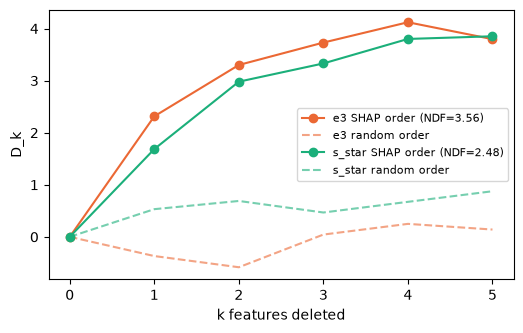

{'e3': {'ndf': 3.5565414960803237, 'G': 0.06203074312583623, 'K': 5},
 's_star': {'ndf': 2.4822582822470265, 'G': 0.11226960739078651, 'K': 5}}

In [8]:
res = {m: metrics_xai.ndf(fm.f(m), x, sh[m]['values'][0], b_del, K_max=5, n_random=20, seed=20_000 + i) for m in ['e3', 's_star']}
fig, ax = plt.subplots(figsize=(6, 3.5))
for m, col in [('e3', '#eb6834'), ('s_star', '#1baf7a')]:
    r = res[m]; k = np.arange(1, r['K'] + 1)
    ax.plot(np.r_[0, k], np.r_[0, r['D_expl']], '-o', color=col, label=f"{m} SHAP order (NDF={r['ndf']:.2f})")
    ax.plot(np.r_[0, k], np.r_[0, r['D_rand_mean']], '--', color=col, alpha=.6, label=f'{m} random order')
ax.set_xlabel('k features deleted'); ax.set_ylabel('D_k'); ax.legend(fontsize=8); plt.show()
{m: {k: res[m][k] for k in ['ndf', 'G', 'K']} for m in res}

## 5. Results of the full experiment (all 75 folds)
The full run (`python scripts/04_run_confirmatory.py`) wrote one JSON file per fold to `results/confirmatory/raw/`. Here they are loaded and the two primary tests are computed.

In [9]:
RAW = ROOT / 'results' / 'confirmatory' / 'raw'
files = sorted(RAW.glob('*_fold*.json')); print(len(files), 'fold files')
F = [json.loads(p.read_text()) for p in files]
pred = pd.DataFrame([{'dataset': f['dataset'], 'fold': f['fold_id'], 'model': m, **v} for f in F for m, v in f['predictive'].items()])
pred.pivot_table(index='model', columns='dataset', values='auc', aggfunc='mean').round(4)

75 fold files


dataset,cleveland,dr_debrecen,wdbc
model,,,
e1,0.9062,0.7966,0.9948
e2,0.9076,0.8123,0.9949
e3,0.9062,0.7984,0.9948
knn,0.8947,0.6989,0.9910
lr,0.9084,0.8018,0.9942
rf,0.8996,0.7536,0.9910
s_star,0.9033,0.8018,0.9931
svm,0.8981,0.7734,0.9945
xgb,0.8736,0.7671,0.9921


In [10]:
spec5 = importlib.util.spec_from_file_location('ana', ROOT / 'scripts' / '05_analyse.py')
ana = importlib.util.module_from_spec(spec5); spec5.loader.exec_module(ana)
out = []
for d in ana.DS:
    p = pred[pred.dataset == d].pivot(index='fold', columns='model', values='auc')
    h1 = ana.corrected_t(p['e3'] - p['s_star'])
    rows = [(f['fold_id'], r) for f in F if f['dataset'] == d for r in f['h2_patients']]
    dd = pd.DataFrame([{'fold': fo, 'd': r['e3']['ndf'] - r['s_star']['ndf']} for fo, r in rows
                       if r['e3']['G'] >= .05 and r['s_star']['G'] >= .05])
    h2 = ana.corrected_t(dd.groupby('fold').d.mean().values)
    out += [{'test': 'H1 ΔAUC', 'dataset': d, **h1}, {'test': 'H2 ΔNDF', 'dataset': d, **h2}]
prim = pd.DataFrame(out)
prim['p_holm'] = prim.apply(lambda r: stats.holm({f"{a}{b}": c for a, b, c in zip(prim.test, prim.dataset, prim.p)})[f"{r.test}{r.dataset}"]['p_holm'], axis=1)
prim[['test', 'dataset', 'mean_diff', 'ci_low', 'ci_high', 'p', 'p_holm']].round(4)

,test,dataset,mean_diff,ci_low,ci_high,p,p_holm
0,H1 ΔAUC,wdbc,0.0017,-0.0038,0.0073,0.5242,1.0000
1,H2 ΔNDF,wdbc,-0.0556,-0.1345,0.0232,0.1585,0.7925
2,H1 ΔAUC,dr_debrecen,-0.0035,-0.0254,0.0185,0.7478,1.0000
3,H2 ΔNDF,dr_debrecen,-0.6929,-1.0748,-0.3110,0.0010,0.0060
4,H1 ΔAUC,cleveland,0.0029,-0.0141,0.0198,0.7302,1.0000
5,H2 ΔNDF,cleveland,-0.0758,-0.2602,0.1087,0.4049,1.0000


## Where the code is
| File | What it does |
|---|---|
| `src/xhe/data.py` | loads and verifies the UCI files |
| `src/xhe/models.py` | model pipelines, S*, ensembles |
| `src/xhe/explain.py` | SHAP and LIME |
| `src/xhe/metrics_xai.py` | NDF, robustness |
| `src/xhe/stats.py` | corrected t-test, Holm, Wilcoxon |
| `scripts/04_run_confirmatory.py` | full experiment (all folds) |
| `scripts/05_analyse.py` | statistics, tables, figures |